  invoice_no customer_id  gender  age  category  quantity    price  \
0    I138884     C241288  Female   28  Clothing         5  1500.40   
1    I317333     C111565    Male   21     Shoes         3  1800.51   
2    I127801     C266599    Male   20  Clothing         1   300.08   
3    I173702     C988172  Female   66     Shoes         5  3000.85   
4    I337046     C189076  Female   53     Books         4    60.60   

  payment_method invoice_date   shopping_mall  
0    Credit Card     5/8/2022          Kanyon  
1     Debit Card   12/12/2021  Forum Istanbul  
2           Cash    9/11/2021       Metrocity  
3    Credit Card   16/05/2021    Metropol AVM  
4           Cash   24/10/2021          Kanyon  
      invoice_no customer_id  gender  age         category  quantity    price  \
99452    I219422     C441542  Female   45         Souvenir         5    58.65   
99453    I325143     C569580    Male   27  Food & Beverage         2    10.46   
99454    I824010     C103292    Male   63  Food 

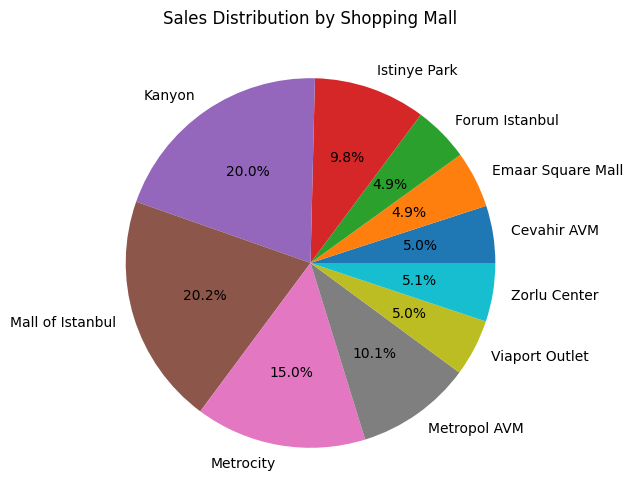

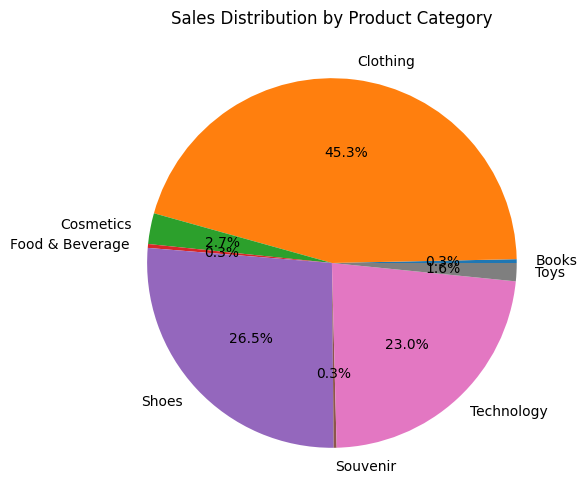

Top Performing Branches:
shopping_mall
Mall of Istanbul     13851737.62
Kanyon               13710755.24
Metrocity            10249980.07
Metropol AVM          6937992.99
Istinye Park          6717077.54
Zorlu Center          3509649.02
Cevahir AVM           3433671.84
Viaport Outlet        3414019.46
Emaar Square Mall     3390408.31
Forum Istanbul        3336073.82
Name: price, dtype: float64
Top Selling Categories:
category
Clothing           31075684.64
Shoes              18135336.89
Technology         15772050.00
Cosmetics           1848606.90
Toys                1086704.64
Food & Beverage      231568.71
Books                226977.30
Souvenir             174436.83
Name: price, dtype: float64
Sales by Branch and Product Category:
shopping_mall  category       
Cevahir AVM    Books                11998.80
               Clothing           1554414.40
               Cosmetics            88394.84
               Food & Beverage      11992.39
               Shoes               884050.41


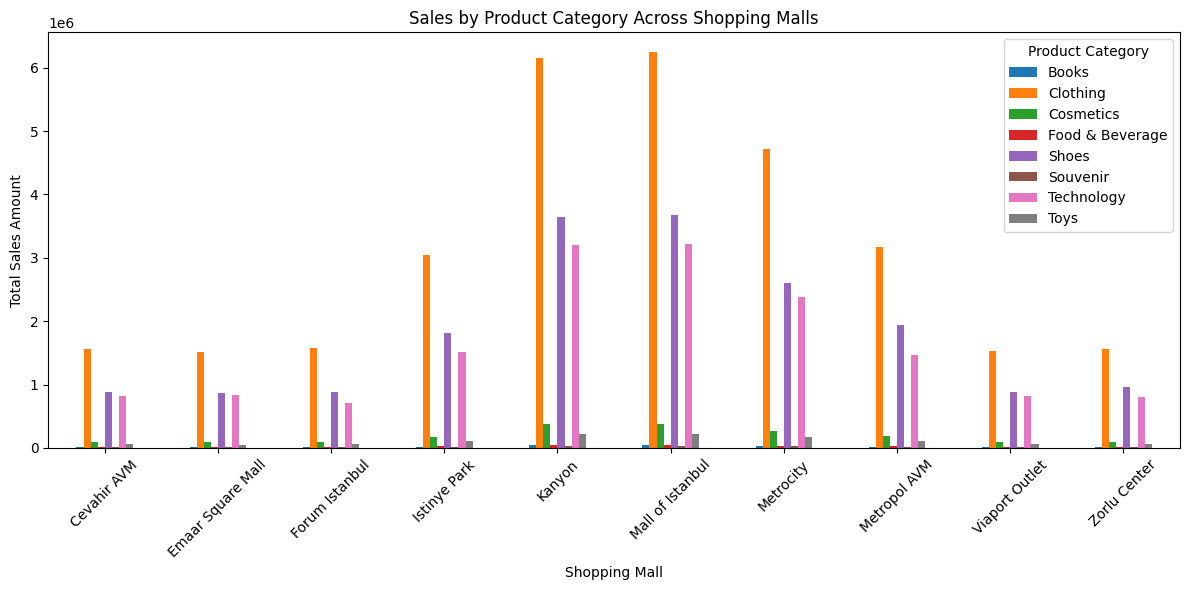

In [ ]:

# Experiment: Data Aggregation - Sales Performance Analysis

import pandas as pd
import matplotlib.pyplot as plt

# 1. Import dataset
df = pd.read_csv("customer_shopping_data.csv")

# 2. Explore the dataset
print(df.head())
print(df.tail())
print(df.info())

# 3. Identify relevant variables
# shopping_mall = Region/Branch
# price = Sales Amount
# category = Product Category

# Count of records grouped by shopping mall
print(df.groupby("shopping_mall").count())

# Count of records grouped by product category
print(df.groupby("category").count())

# 4. Calculate total sales for each branch
branch_sales = df.groupby("shopping_mall")["price"].sum()
print("Total Sales by Branch:")
print(branch_sales)

# Calculate total sales for each product category
category_sales = df.groupby("category")["price"].sum()
print("Total Sales by Category:")
print(category_sales)

# 5. Pie chart for sales by branch
plt.figure(figsize=(8, 6))
plt.pie(branch_sales, labels=branch_sales.index, autopct="%1.1f%%")
plt.title("Sales Distribution by Shopping Mall")
plt.show()

# Pie chart for sales by product category
plt.figure(figsize=(8, 6))
plt.pie(category_sales, labels=category_sales.index, autopct="%1.1f%%")
plt.title("Sales Distribution by Product Category")
plt.show()

# 6. Identify top-performing branches
print("Top Performing Branches:")
print(branch_sales.sort_values(ascending=False))

# Identify top-selling categories
print("Top Selling Categories:")
print(category_sales.sort_values(ascending=False))

# 7. Total sales by branch and product category
combined_branch_category_sales = df.groupby(
    ["shopping_mall", "category"]
)["price"].sum()

print("Sales by Branch and Product Category:")
print(combined_branch_category_sales)

# 8. Create pivot table for comparison
combined_pivot = df.pivot_table(
    index="shopping_mall",
    columns="category",
    values="price",
    aggfunc="sum"
)

print(combined_pivot)

# Grouped bar chart
combined_pivot.plot(kind="bar", figsize=(12, 6))
plt.title("Sales by Product Category Across Shopping Malls")
plt.xlabel("Shopping Mall")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.legend(title="Product Category")
plt.tight_layout()
plt.show()
